# 04 - Covariance matrix stability (Test 2)

**Research question.** Is the covariance structure that optimisers rely on stable over time and well-conditioned?

**Tools.** Eigenvalues/eigenvectors, condition number, the Marchenko-Pastur noise edge, eigenvector rotation across windows, Ledoit-Wolf shrinkage intensity, and Box's M test of equal covariances.

For a pure-noise correlation matrix with $q=N/T$, eigenvalues concentrate in $[(1-\sqrt q)^2,(1+\sqrt q)^2]$. Sample eigenvalues above the upper edge may be signal; the rest are statistically indistinguishable from noise.

In [4]:
import sys, warnings
import os
from pathlib import Path
try:  # VS Code defines this: always run from this notebook's own folder
    os.chdir(Path(__vsc_ipynb_file__).resolve().parent)
except NameError:  # classic Jupyter already starts in the notebook's folder
    pass
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import data_processing as dp, covariance_estimators as ce, portfolio_models as pm
from src import stability_tests as st, regime_detection as rd, stress_testing as sx, evaluation as ev
plt.rcParams["figure.dpi"] = 110
_candidates = ["returns_simple_daily.csv"]
_path = next((Path("../data/processed") / f for f in _candidates if (Path("../data/processed") / f).exists()), None)
if _path is None:
    raise FileNotFoundError("Run notebook 01 first: expected ../data/processed/returns_simple_daily.csv")
returns = pd.read_csv(_path, index_col=0, parse_dates=True)
print("loaded:", _path.name)
X = returns.to_numpy()
print(returns.shape, returns.index[0].date(), "->", returns.index[-1].date())

loaded: returns_simple_daily.csv
(3519, 5) 2012-01-04 -> 2025-12-31


## 1. Spectrum of the full-sample correlation matrix vs the noise edge

eigenvalues above the noise edge: 2 of 5


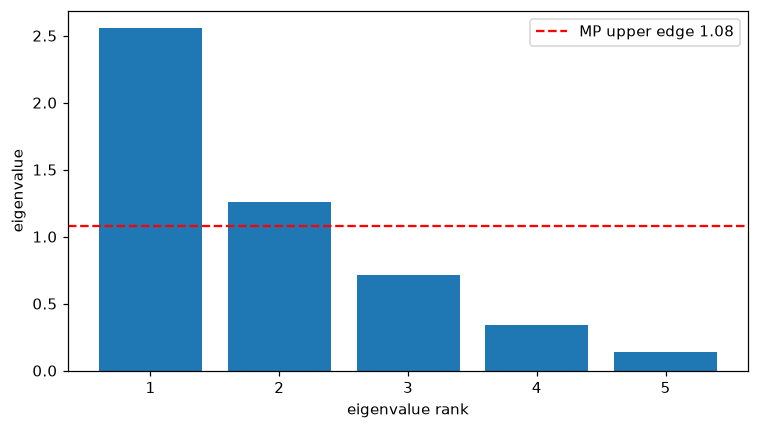

In [5]:
C = ce.to_correlation(ce.sample_covariance(X))
vals = np.sort(np.linalg.eigvalsh(C))[::-1]
lo, hi = st.marchenko_pastur_edges(T=len(X), N=X.shape[1])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(vals) + 1), vals); ax.axhline(hi, color="r", ls="--", label=f"MP upper edge {hi:.2f}")
ax.set_xlabel("eigenvalue rank"); ax.set_ylabel("eigenvalue"); ax.legend(); plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\covariance_spectrum_mp.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")
print("eigenvalues above the noise edge:", int((vals > hi).sum()), "of", len(vals))

**Interpret:** how many factors does the data support? The MP edge assumes iid noise - why is that assumption too kind for financial returns (think volatility clustering)?

## 2. Rolling diagnostics

,condition_number,pc1_share,mean_corr,min_eig
count,156.000,156.000,156.000,156.0
mean,62.774,0.617,0.290,0.0
std,28.742,0.098,0.107,0.0
min,18.104,0.404,0.114,0.0
25%,38.945,0.551,0.200,0.0
50%,60.368,0.613,0.285,0.0
75%,78.609,0.663,0.378,0.0
max,130.543,0.849,0.533,0.0


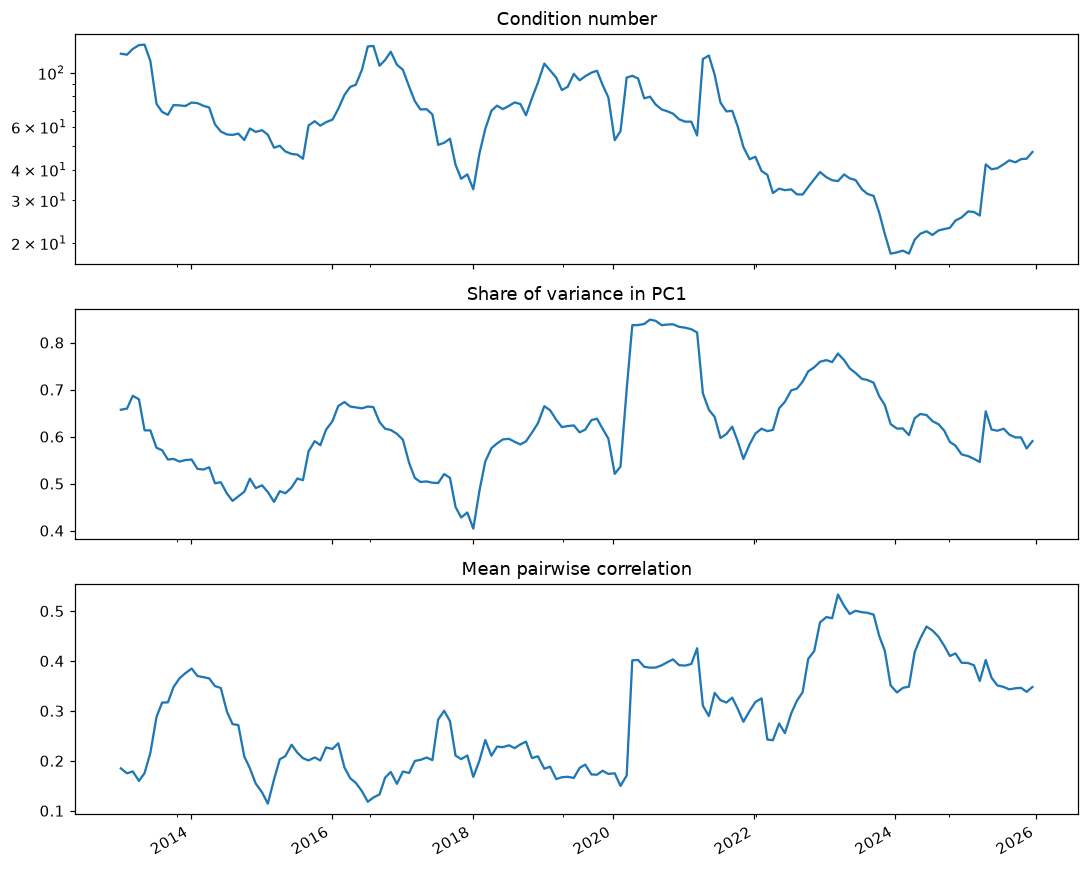

In [11]:
diag = st.rolling_covariance_diagnostics(returns, window=252, step=21)
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
diag["condition_number"].plot(ax=ax[0], logy=True, title="Condition number")
diag["pc1_share"].plot(ax=ax[1], title="Share of variance in PC1")
diag["mean_corr"].plot(ax=ax[2], title="Mean pairwise correlation"); plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\rolling_covariance_diagnostics.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")
diag_summary = diag.describe().round(3)
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\rolling_covariance_diagnostics_summary.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
diag_summary.to_csv(table_path)
diag_summary

**Interpret:** when do conditions deteriorate and correlations rise? Does the time-variation look like noise around a constant or like regimes?

**Interpretation** Conditions worsened and correlations rose sharply around 2020 and 2023, suggesting periods of market stress. The clear shifts look more like regimes than random noise.

## 3. Eigenvector stability

,pc1,pc2,pc3
count,155.000,155.000,155.000
mean,0.995,0.987,0.990
std,0.019,0.045,0.040
min,0.794,0.542,0.542
25%,0.998,0.993,0.995
50%,0.999,0.998,0.998
75%,1.000,0.999,0.999
max,1.000,1.000,1.000


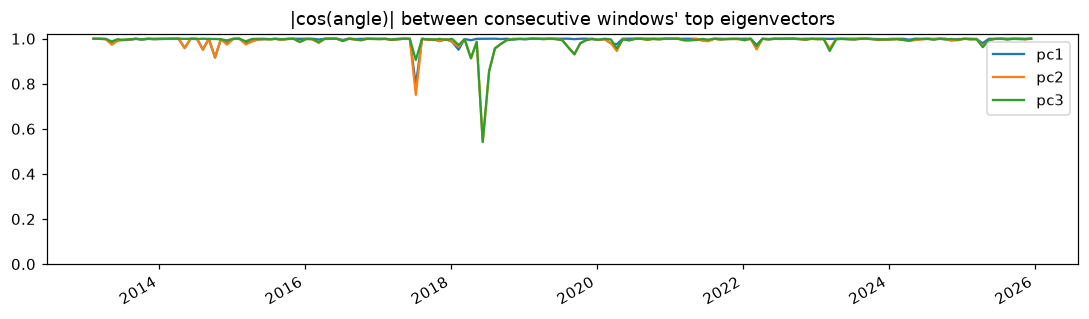

In [12]:
ev_stab = st.eigenvector_stability(returns, window=252, step=21, k=3)
ax = ev_stab.plot(figsize=(10, 3), title="|cos(angle)| between consecutive windows' top eigenvectors")
ax.set_ylim(0, 1.02)
fig = ax.get_figure()
plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\eigenvector_stability.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")
ev_stab_summary = ev_stab.describe().round(3)
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\eigenvector_stability_summary.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
ev_stab_summary.to_csv(table_path)
ev_stab_summary

**Interpret:** values near 1 mean a window-to-window stable principal direction. Which principal component is most stable and why (economic story)? What does instability of PC2/PC3 imply for optimisers that exploit low-variance directions?

**Interpretation** PC1 is most stable (mean similarity 0.995), likely reflecting a persistent broad market factor. PC2 and PC3 are also stable on average, but occasional sharp drops show their directions can shift. Optimizers relying on these lower-variance components may therefore produce fragile weights that change sharply over time.

## 4. Shrinkage intensity over time and condition numbers

,lw_intensity,cond_sample,cond_LW
count,52.000,52.000,52.000
mean,0.059,63.371,28.380
std,0.034,29.689,10.839
min,0.021,18.331,11.300
25%,0.036,41.019,22.291
50%,0.048,61.544,26.240
75%,0.072,76.583,32.796
max,0.170,129.957,57.565


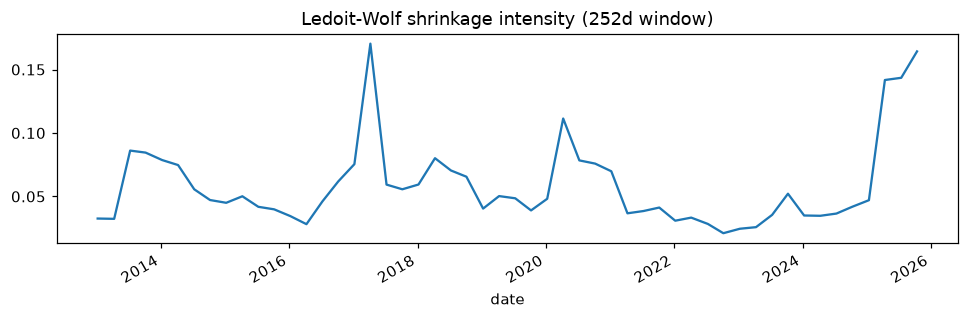

In [13]:
rows = []
for i in range(252, len(returns) + 1, 63):
    w_ = X[i - 252:i]
    rows.append({"date": returns.index[i - 1],
                 "lw_intensity": ce.ledoit_wolf_shrinkage_intensity(w_),
                 "cond_sample": ce.condition_number(ce.sample_covariance(w_)),
                 "cond_LW": ce.condition_number(ce.ledoit_wolf_covariance(w_))})
sh = pd.DataFrame(rows).set_index("date")
ax = sh["lw_intensity"].plot(figsize=(9, 3), title="Ledoit-Wolf shrinkage intensity (252d window)")
fig = ax.get_figure()
plt.tight_layout()
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\ledoit_wolf_shrinkage_intensity.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")
sh_summary = sh.describe().round(3)
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\ledoit_wolf_shrinkage_intensity_summary.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
sh_summary.to_csv(table_path)
sh_summary

## 5. Did the covariance matrix change? Box's M across sub-periods
Box's M is sensitive to non-normality, so treat a rejection as *consistent with* instability, not proof. Pair it with the Frobenius distance, an effect-size measure.

In [14]:
half = len(X) // 2
b = st.box_m_test(X[:half], X[half:])
S1, S2 = ce.sample_covariance(X[:half]), ce.sample_covariance(X[half:])
print("Box M:", {k: round(v, 4) for k, v in b.items()})
print("relative Frobenius change:", round(st.frobenius_change(S1, S2), 3))
print("condition numbers:", round(ce.condition_number(S1), 1), round(ce.condition_number(S2), 1))

Box M: {'statistic': 1642.6608, 'dof': 15.0, 'p_value': 0.0}
relative Frobenius change: 1.244
condition numbers: 67.0 36.0


**Your turn - critical thinking.**
1. A huge sample makes Box's M reject trivially. Why is the Frobenius change a better guide to economic relevance, and what would you add (e.g. the change in the *optimal weights* when swapping $S_1$ for $S_2$)?
2. Compute that weight change yourself: `pm.gmv_long_only` using `ce.sample_covariance` of each half, then 0.5*L1 distance.

In [15]:
w1, w2 = pm.gmv_long_only(X[:half]), pm.gmv_long_only(X[half:])
print("turnover-equivalent between halves:", round(0.5 * np.abs(w1 - w2).sum(), 3))

turnover-equivalent between halves: 0.041
